# 1. Đọc dữ liệu và kiểm tra khả năng áp dụng IQR

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Tìm dataset gốc
DATA_PATH = None

for folder in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    candidate = folder / "data" / "raw" / "RT_IOT2022.csv"

    if candidate.exists():
        DATA_PATH = candidate
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "Không tìm thấy data/raw/RT_IOT2022.csv"
    )

ROOT = DATA_PATH.parent.parent.parent

FIG_DIR = ROOT / "results" / "EDA" / "figures"
TABLE_DIR = ROOT / "results" / "EDA" / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Đọc dữ liệu, không chỉnh sửa dataset
df = pd.read_csv(DATA_PATH)

# Lấy các thuộc tính số, bỏ cột chỉ số
num = df.select_dtypes(include=np.number).drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

# Tính các phân vị
q1 = num.quantile(0.25)
q3 = num.quantile(0.75)
iqr = q3 - q1

iqr_summary = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "Zero (%)": num.eq(0).mean() * 100,
    "Unique Values": num.nunique()
})

iqr_summary["IQR = 0"] = iqr_summary["IQR"] == 0

print("=== KIỂM TRA IQR ===")
print("Tổng đặc trưng số:", num.shape[1])
print("Số cột IQR > 0:", (iqr > 0).sum())
print("Số cột IQR = 0:", (iqr == 0).sum())

print("\n=== CÁC CỘT IQR = 0 ===")
display(
    iqr_summary[
        iqr_summary["IQR = 0"]
    ].round(4)
)

iqr_summary.to_csv(
    TABLE_DIR / "03_iqr_summary.csv",
    encoding="utf-8-sig"
)

=== KIỂM TRA IQR ===
Tổng đặc trưng số: 81
Số cột IQR > 0: 15
Số cột IQR = 0: 66

=== CÁC CỘT IQR = 0 ===


,Q1,Q3,IQR,Zero (%),Unique Values,IQR = 0
id.resp_p,21.0,21.0,0.0,0.0114,1809,True
fwd_pkts_tot,1.0,1.0,0.0,0.0357,163,True
bwd_pkts_tot,1.0,1.0,0.0,12.3687,172,True
fwd_data_pkts_tot,1.0,1.0,0.0,5.5289,116,True
bwd_data_pkts_tot,0.0,0.0,0.0,85.7696,154,True
...,...,...,...,...,...,...
idle.avg,0.0,0.0,0.0,95.3727,5670,True
idle.std,0.0,0.0,0.0,99.1740,1001,True
fwd_init_window_size,64.0,64.0,0.0,10.3170,20,True
bwd_init_window_size,0.0,0.0,0.0,91.5861,56,True


### Nhận xét: Khảo sát IQR

**Kết quả phân tích:**

- Dataset có 81 đặc trưng số khi không tính
  cột `Unnamed: 0`.
- Có 15 đặc trưng có IQR > 0.
- Có 66 đặc trưng có IQR = 0.
- Nhiều đặc trưng có Q1 và Q3 bằng nhau,
  cho thấy ít nhất 50% dữ liệu nằm tập trung
  tại cùng một giá trị hoặc khoảng rất hẹp.

**Vấn đề phát hiện:**

1. Phần lớn đặc trưng không có độ phân tán
   trong khoảng giữa Q1 và Q3.
2. Một số đặc trưng có nhiều giá trị 0
   hoặc giá trị lặp lại.
3. Khi IQR = 0, quy tắc phát hiện ngoại lệ
   bằng 1,5 × IQR có thể đánh dấu quá nhiều
   giá trị khác giá trị phổ biến.
4. Do đó, phương pháp IQR không phù hợp
   để áp dụng máy móc cho tất cả đặc trưng.

**Kết luận:**

Cần phân biệt các đặc trưng có IQR > 0
và IQR = 0 trước khi phân tích ngoại lệ.

Những đặc trưng có IQR = 0 không nhất thiết
là đặc trưng vô ích hoặc cần loại bỏ.

# 2. Phát hiện ngoại lệ bằng IQR

=== NGOẠI LỆ THEO IQR ===


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier (%)
flow_iat.avg,0.9537,5.006800e+00,4.053100e+00,-5.126000e+00,1.108650e+01,19180,15.5787
flow_iat.tot,0.9537,5.006800e+00,4.053100e+00,-5.126000e+00,1.108650e+01,19180,15.5787
flow_iat.max,0.9537,5.006800e+00,4.053100e+00,-5.126000e+00,1.108650e+01,19180,15.5787
flow_duration,0.0000,0.000000e+00,0.000000e+00,-0.000000e+00,0.000000e+00,19171,15.5714
active.max,0.9537,5.006800e+00,4.053100e+00,-5.126000e+00,1.108650e+01,19165,15.5665
active.tot,0.9537,5.006800e+00,4.053100e+00,-5.126000e+00,1.108650e+01,19165,15.5665
active.avg,0.9537,5.006800e+00,4.053100e+00,-5.126000e+00,1.108650e+01,19165,15.5665
active.min,0.9537,5.006800e+00,4.053100e+00,-5.126000e+00,1.108650e+01,18906,15.3561
flow_iat.min,0.9537,5.006800e+00,4.053100e+00,-5.126000e+00,1.108650e+01,15205,12.3500
flow_pkts_payload.std,50.2195,8.485280e+01,3.463330e+01,-1.730400e+00,1.368028e+02,5896,4.7889



=== TOP 10 CỘT CÓ NHIỀU GIÁ TRỊ NGOẠI LỆ ===


,Outlier Count,Outlier (%)
flow_iat.avg,19180,15.58
flow_iat.tot,19180,15.58
flow_iat.max,19180,15.58
flow_duration,19171,15.57
active.max,19165,15.57
active.tot,19165,15.57
active.avg,19165,15.57
active.min,18906,15.36
flow_iat.min,15205,12.35
flow_pkts_payload.std,5896,4.79


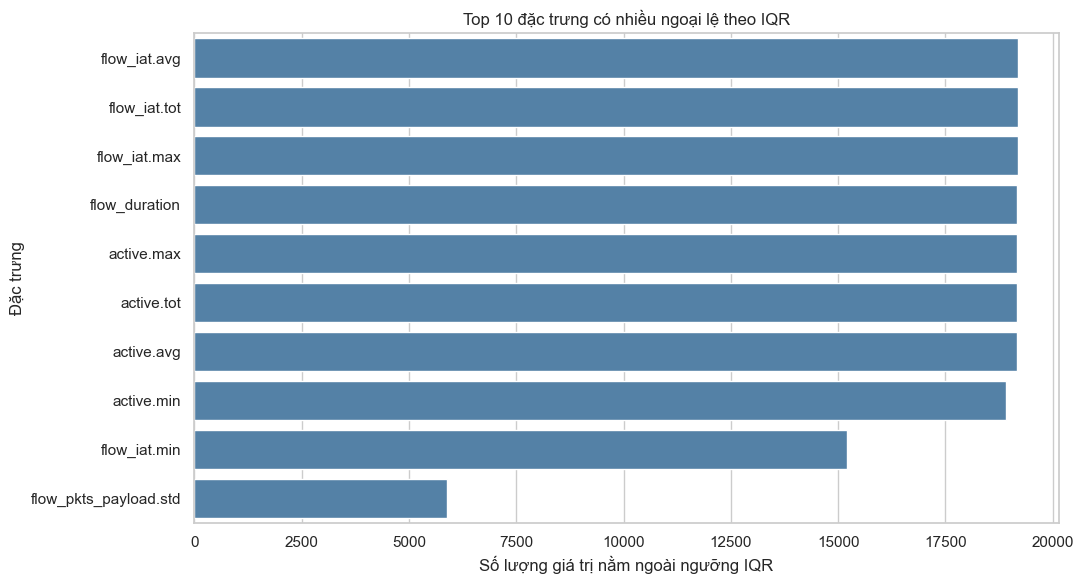

In [2]:
valid_cols = iqr[iqr > 0].index

lower_bound = q1[valid_cols] - 1.5 * iqr[valid_cols]
upper_bound = q3[valid_cols] + 1.5 * iqr[valid_cols]

# Đánh dấu giá trị nằm ngoài khoảng IQR
outlier_mask = (
    num[valid_cols].lt(lower_bound) |
    num[valid_cols].gt(upper_bound)
)

outlier_count = outlier_mask.sum()

outlier_result = pd.DataFrame({
    "Q1": q1[valid_cols],
    "Q3": q3[valid_cols],
    "IQR": iqr[valid_cols],
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound,
    "Outlier Count": outlier_count,
    "Outlier (%)": outlier_count / len(df) * 100
})

outlier_result = outlier_result.sort_values(
    "Outlier Count",
    ascending=False
)

print("=== NGOẠI LỆ THEO IQR ===")
display(outlier_result.round(4))

print("\n=== TOP 10 CỘT CÓ NHIỀU GIÁ TRỊ NGOẠI LỆ ===")

display(
    outlier_result[
        ["Outlier Count", "Outlier (%)"]
    ].head(10).round(2)
)

# Vẽ số lượng ngoại lệ
top10 = outlier_result.head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=top10["Outlier Count"].values,
    y=top10.index,
    color="steelblue"
)

plt.title("Top 10 đặc trưng có nhiều ngoại lệ theo IQR")
plt.xlabel("Số lượng giá trị nằm ngoài ngưỡng IQR")
plt.ylabel("Đặc trưng")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "03_iqr_outlier_counts.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

outlier_result.to_csv(
    TABLE_DIR / "03_iqr_outlier_results.csv",
    encoding="utf-8-sig"
)

### Nhận xét: Phát hiện ngoại lệ bằng IQR

**Kết quả phân tích:**

Trong 15 đặc trưng có IQR > 0:

- `flow_iat.avg`: 19.180 giá trị nằm ngoài
  ngưỡng IQR.
- `flow_iat.tot`: 19.180 giá trị.
- `flow_iat.max`: 19.180 giá trị.
- `flow_duration`: 19.171 giá trị.
- `active.max`: 19.165 giá trị.

**Vấn đề phát hiện:**

1. Một số đặc trưng có khoảng 15–16% số mẫu
   nằm ngoài ngưỡng IQR.
2. Giá trị trung tâm của nhiều đặc trưng
   tập trung trong khoảng rất hẹp.
3. Các giá trị nằm ngoài ngưỡng IQR
   chưa chắc là dữ liệu sai.
4. Trong bài toán phát hiện tấn công mạng,
   những giá trị bất thường có thể mang
   thông tin quan trọng về hành vi tấn công.

**Kết luận:**

Phát hiện nhiều giá trị bất thường theo
quy tắc IQR ở các đặc trưng liên quan
đến thời gian và hoạt động lưu lượng mạng.

# 3. Boxplot: trực quan hóa ngoại lệ

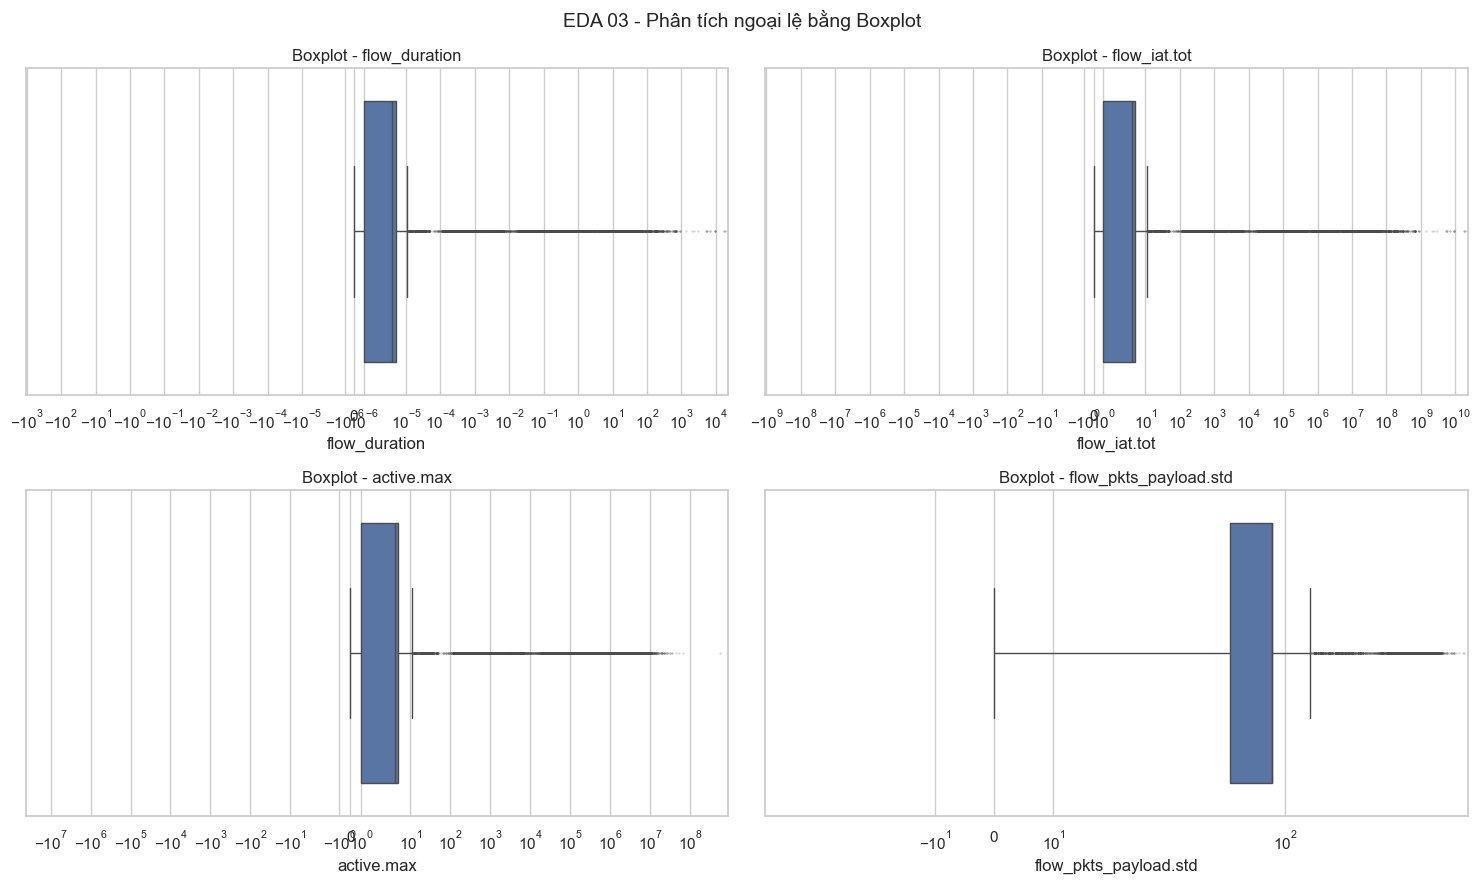

In [5]:
selected_features = [
    "flow_duration",
    "flow_iat.tot",
    "active.max",
    "flow_pkts_payload.std"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 9)
)

for ax, col in zip(axes.flat, selected_features):

    sns.boxplot(
        x=num[col],
        ax=ax,
        showfliers=True,
        flierprops={
            "marker": ".",
            "markersize": 1,
            "alpha": 0.3
        }
    )

    # Chỉ đổi thang trục để quan sát rõ hơn
    ax.set_xscale(
        "symlog",
        linthresh=max(float(iqr[col]), 1e-6)
    )

    ax.set_title(f"Boxplot - {col}")
    ax.set_xlabel(col)

plt.suptitle(
    "EDA 03 - Phân tích ngoại lệ bằng Boxplot",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "03_boxplot_outliers.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Nhận xét: Boxplot

**Kết quả phân tích:**

- `flow_duration` có phần lớn giá trị tập trung
  trong khoảng rất nhỏ, nhưng vẫn xuất hiện
  những giá trị lớn hơn rất nhiều.
- `flow_iat.tot` có sự chênh lệch lớn giữa
  vùng dữ liệu trung tâm và các giá trị cực đại.
- `active.max` cũng xuất hiện nhiều giá trị
  nằm ngoài khoảng IQR.
- `flow_pkts_payload.std` cho thấy sự phân tán
  của các giá trị thống kê payload.

**Vấn đề phát hiện:**

1. Phân phối của một số đặc trưng có đuôi dài.
2. Có nhiều giá trị nằm ngoài ngưỡng IQR.
3. Khoảng biến thiên giữa các đặc trưng
   khác nhau đáng kể.
4. Những giá trị bất thường có thể phản ánh
   hành vi mạng khác với phần lớn dữ liệu.

**Kết luận:**

Boxplot xác nhận sự tồn tại của nhiều giá trị
bất thường theo quy tắc thống kê.

Tuy nhiên, đối với dữ liệu tấn công mạng,
không thể mặc định những giá trị này là nhiễu.

Cần tiếp tục kiểm tra mối quan hệ giữa
ngoại lệ và nhãn Attack_type trước khi
đưa ra quyết định xử lý.

# 4. Correlation Analysis: Pearson và Spearman

In [6]:
# Loại cột hằng khỏi phép tính tương quan
# Không xóa cột khỏi dataset gốc
corr_data = num.loc[
    :, num.nunique(dropna=False) > 1
]

print("Số đặc trưng dùng tính tương quan:",
      corr_data.shape[1])

# Tính Pearson
pearson_corr = corr_data.corr(method="pearson")

# Tính Spearman
spearman_corr = corr_data.corr(method="spearman")

# Chỉ lấy mỗi cặp một lần, bỏ đường chéo
mask = np.triu(
    np.ones(pearson_corr.shape, dtype=bool),
    k=1
)

pearson_pairs = (
    pearson_corr
    .where(mask)
    .stack()
    .rename("Pearson")
)

spearman_pairs = (
    spearman_corr
    .where(mask)
    .stack()
    .rename("Spearman")
)

# Gộp kết quả
corr_pairs = pd.concat(
    [pearson_pairs, spearman_pairs],
    axis=1
).reset_index()

corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Pearson",
    "Spearman"
]

corr_pairs["Abs Pearson"] = (
    corr_pairs["Pearson"].abs()
)

corr_pairs["Abs Spearman"] = (
    corr_pairs["Spearman"].abs()
)

print("=== PHÂN TÍCH TƯƠNG QUAN ===")

print(
    "Số cặp |Pearson| >= 0.95:",
    (corr_pairs["Abs Pearson"] >= 0.95).sum()
)

print(
    "Số cặp |Spearman| >= 0.95:",
    (corr_pairs["Abs Spearman"] >= 0.95).sum()
)

print("\n=== TOP 20 CẶP PEARSON CAO NHẤT ===")

display(
    corr_pairs.sort_values(
        "Abs Pearson",
        ascending=False
    ).head(20).round(6)
)

# Lưu bảng kết quả
corr_pairs.to_csv(
    TABLE_DIR / "03_correlation_pairs.csv",
    index=False,
    encoding="utf-8-sig"
)

Số đặc trưng dùng tính tương quan: 80
=== PHÂN TÍCH TƯƠNG QUAN ===
Số cặp |Pearson| >= 0.95: 52
Số cặp |Spearman| >= 0.95: 180

=== TOP 20 CẶP PEARSON CAO NHẤT ===


,Feature 1,Feature 2,Pearson,Spearman,Abs Pearson,Abs Spearman
207,flow_duration,flow_iat.tot,1.000000,0.991995,1.000000,0.991995
604,bwd_pkts_per_sec,flow_pkts_per_sec,0.999997,0.999374,0.999997,0.999374
533,fwd_pkts_per_sec,flow_pkts_per_sec,0.999997,0.999963,0.999997,0.999963
532,fwd_pkts_per_sec,bwd_pkts_per_sec,0.999986,0.999269,0.999986,0.999269
3008,bwd_bulk_bytes,bwd_bulk_packets,0.999802,0.999990,0.999802,0.999990
2802,flow_iat.max,idle.max,0.999748,0.367386,0.999748,0.367386
2503,fwd_iat.tot,flow_iat.tot,0.999719,0.612563,0.999719,0.612563
197,flow_duration,fwd_iat.tot,0.999719,0.617503,0.999719,0.617503
2466,fwd_iat.max,flow_iat.max,0.996647,0.612307,0.996647,0.612307
2487,fwd_iat.max,idle.max,0.996389,0.596791,0.996389,0.596791


### Nhận xét: Pearson và Spearman Correlation
**Kết quả phân tích:**

Sau khi loại cột hằng khỏi phép tính tương quan:

- Phát hiện 52 cặp đặc trưng có
  |Pearson| >= 0.95.
- Phát hiện 180 cặp đặc trưng có
  |Spearman| >= 0.95.

Một số cặp có tương quan Pearson rất cao:

1. `flow_duration` và `flow_iat.tot`.
2. `bwd_pkts_per_sec` và `flow_pkts_per_sec`.
3. `fwd_pkts_per_sec` và `flow_pkts_per_sec`.
4. `bwd_bulk_bytes` và `bwd_bulk_packets`.
5. `flow_iat.max` và `idle.max`.

**Vấn đề phát hiện:**

1. Dataset tồn tại nhiều cặp đặc trưng có
   quan hệ tuyến tính hoặc đơn điệu rất mạnh.
2. Một số đặc trưng có khả năng chứa
   thông tin tương tự hoặc được tính toán
   từ những đại lượng liên quan.
3. Điều này làm xuất hiện nguy cơ dư thừa
   thông tin trong tập đặc trưng đầu vào.
4. Số cặp tương quan cao theo Spearman
   lớn hơn Pearson, cho thấy nhiều mối
   quan hệ đơn điệu không nhất thiết tuyến tính.

**Kết luận:**

Tập dữ liệu có dấu hiệu dư thừa đặc trưng.

Tuy nhiên, tương quan cao không đồng nghĩa
hai đặc trưng hoàn toàn giống nhau hoặc
một trong hai chắc chắn không có giá trị.

Cần xem xét thử Correlation Filter
trong giai đoạn thực nghiệm và đánh giá
ảnh hưởng đến hiệu quả MLP.

# 5. Correlation Heatmap và kiểm tra cặp đặc trưng tương quan cao

Các đặc trưng được chọn:
['flow_duration', 'bwd_pkts_per_sec', 'fwd_pkts_per_sec', 'bwd_bulk_bytes', 'flow_iat.max', 'fwd_iat.tot', 'fwd_iat.max', 'flow_iat.tot', 'flow_pkts_per_sec', 'bwd_bulk_packets', 'idle.max']


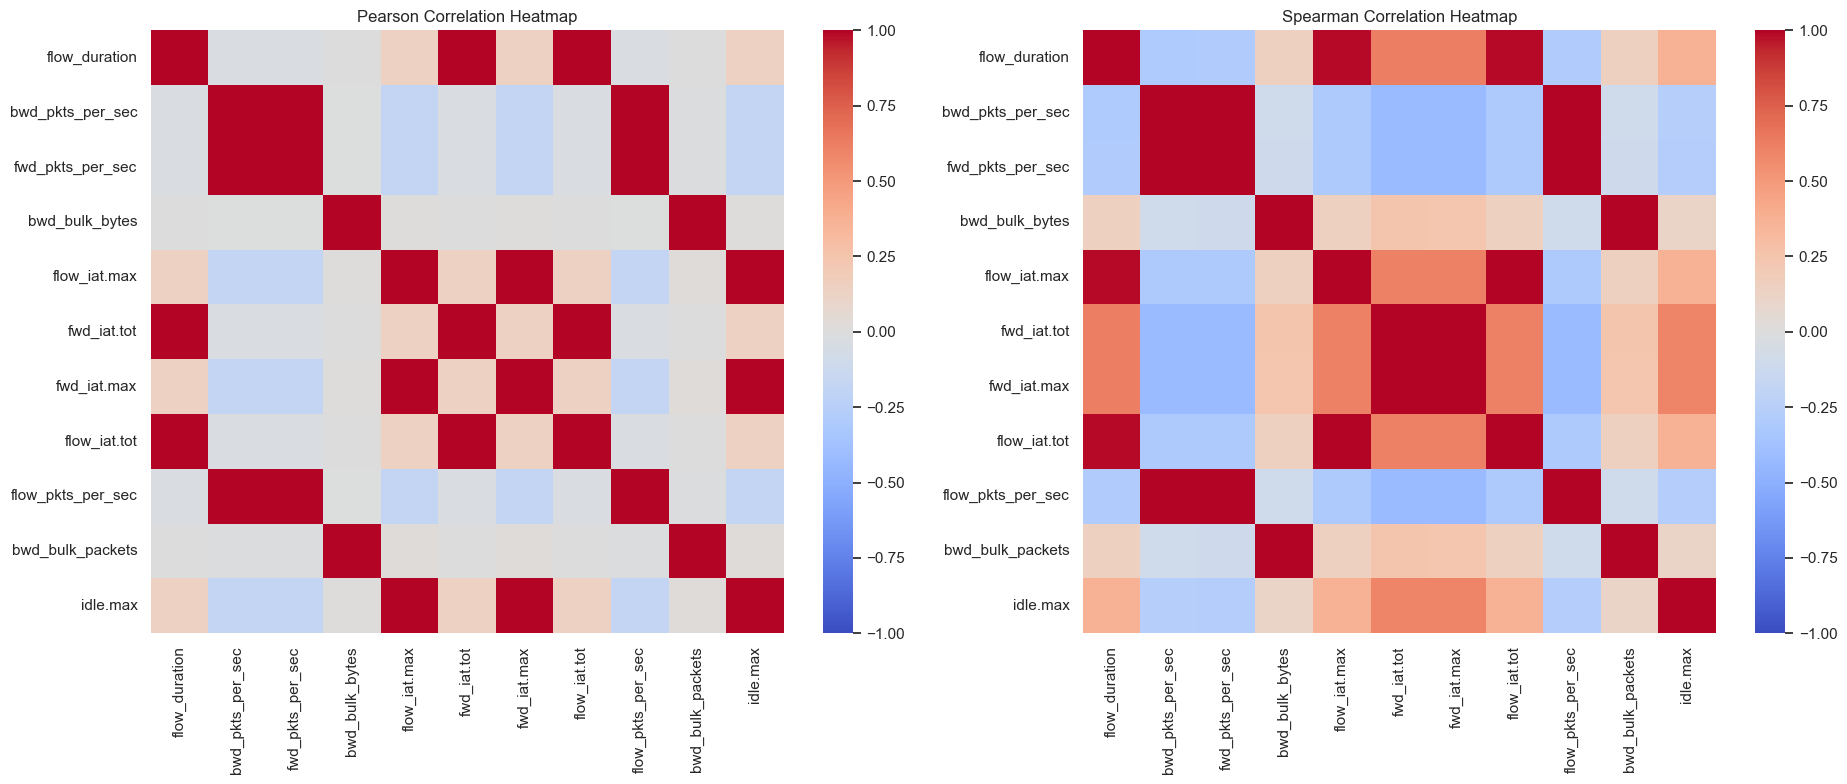


=== KIỂM TRA CẶP ĐẶC TRƯNG ===
Feature 1: flow_duration
Feature 2: flow_iat.tot
Pearson: 0.9999999788564732
Spearman: 0.9919950816275077


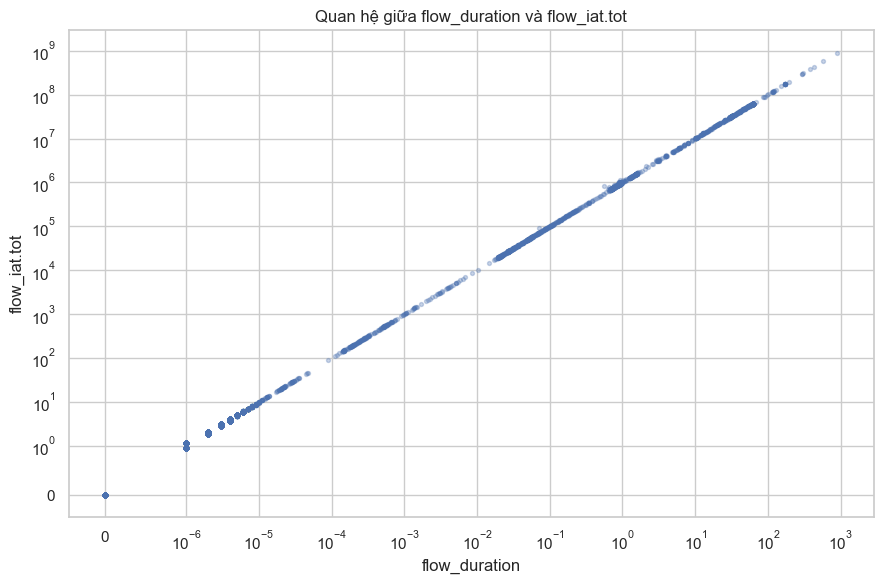

In [7]:
# Chọn 10 cặp có Pearson tuyệt đối lớn nhất
top_pairs = corr_pairs.sort_values(
    "Abs Pearson",
    ascending=False
).head(10)

# Lấy danh sách cột xuất hiện trong 10 cặp
selected_corr_features = list(dict.fromkeys(
    top_pairs["Feature 1"].tolist()
    + top_pairs["Feature 2"].tolist()
))

print("Các đặc trưng được chọn:")
print(selected_corr_features)

fig, axes = plt.subplots(
    1, 2,
    figsize=(19, 8)
)

# Pearson Heatmap
sns.heatmap(
    pearson_corr.loc[
        selected_corr_features,
        selected_corr_features
    ],
    ax=axes[0],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False
)

axes[0].set_title("Pearson Correlation Heatmap")

# Spearman Heatmap
sns.heatmap(
    spearman_corr.loc[
        selected_corr_features,
        selected_corr_features
    ],
    ax=axes[1],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False
)

axes[1].set_title("Spearman Correlation Heatmap")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "03_correlation_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# Kiểm tra chi tiết một cặp đặc trưng
feature_a = "flow_duration"
feature_b = "flow_iat.tot"

print("\n=== KIỂM TRA CẶP ĐẶC TRƯNG ===")

print("Feature 1:", feature_a)
print("Feature 2:", feature_b)

print(
    "Pearson:",
    pearson_corr.loc[feature_a, feature_b]
)

print(
    "Spearman:",
    spearman_corr.loc[feature_a, feature_b]
)

# Quan sát quan hệ bằng Scatterplot
sample = df[
    [feature_a, feature_b]
].sample(
    n=min(10000, len(df)),
    random_state=42
)

plt.figure(figsize=(9, 6))

plt.scatter(
    sample[feature_a],
    sample[feature_b],
    s=8,
    alpha=0.3
)

# Đổi thang hiển thị để dễ quan sát
plt.xscale("symlog", linthresh=1e-6)
plt.yscale("symlog", linthresh=1)

plt.title(
    "Quan hệ giữa flow_duration và flow_iat.tot"
)

plt.xlabel(feature_a)
plt.ylabel(feature_b)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "03_high_correlation_scatter.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Nhận xét: Correlation Heatmap
**Kết quả phân tích:**

- Heatmap cho thấy nhiều nhóm đặc trưng
  có hệ số tương quan gần 1.
- Cặp `flow_duration` và `flow_iat.tot`
  có tương quan tuyến tính gần như tuyệt đối.
- Một số đặc trưng liên quan đến số gói tin,
  tốc độ truyền và thời gian có quan hệ
  rất chặt chẽ.
- Scatterplot giúp quan sát trực tiếp mối
  liên hệ giữa các giá trị của hai đặc trưng.

**Vấn đề phát hiện:**

1. Một số đặc trưng có thể mang thông tin
   trùng lặp hoặc gần trùng lặp.
2. Tập đặc trưng có khả năng chứa nhiều
   thông tin dư thừa.
3. Việc sử dụng tất cả các đặc trưng
   có thể làm tăng độ phức tạp đầu vào.
4. Tương quan cao không chứng minh
   mô hình bị Data Leakage.

**Kết luận:**

Có cơ sở để thử nghiệm phương pháp
Correlation Filter nhằm giảm đặc trưng
dư thừa.

Tuy nhiên, cần đánh giá kết quả mô hình
trước và sau khi loại bỏ các đặc trưng.

Việc lựa chọn đặc trưng phải được thực hiện
trên tập Train trong giai đoạn huấn luyện,
không sử dụng Validation để quyết định
cột nào cần giữ hoặc loại bỏ.

# 6. Tổng hợp kết quả EDA 03 - Outliers & Correlation

### Những vấn đề phát hiện

| Vấn đề | Bằng chứng | Hướng nghiên cứu |
|---|---|---|
| Nhiều đặc trưng có IQR = 0 | 66/81 đặc trưng số | Xem xét phương pháp phát hiện ngoại lệ phù hợp |
| Giá trị nằm ngoài ngưỡng IQR | `flow_iat.tot`: 19.180 mẫu | Kiểm tra ngoại lệ theo từng lớp |
| Phân phối có đuôi dài | Quan sát Boxplot | Thử phương pháp biến đổi và chuẩn hóa phù hợp |
| Tương quan tuyến tính cao | 52 cặp có \|Pearson\| >= 0.95 | Thử Correlation Filter |
| Tương quan đơn điệu cao | 180 cặp có \|Spearman\| >= 0.95 | Kiểm tra quan hệ giữa các đặc trưng |
| Đặc trưng có khả năng dư thừa | `flow_duration` và `flow_iat.tot` | Đánh giá hiệu quả sau chọn đặc trưng |

### Đánh giá chung

Qua phân tích ngoại lệ và tương quan,
phát hiện hai vấn đề nổi bật.

**Thứ nhất: Đặc trưng có phân phối bất thường.**

Nhiều đặc trưng có IQR bằng 0, trong khi
một số đặc trưng khác có nhiều giá trị
nằm ngoài khoảng IQR.

Điều này cho thấy không nên áp dụng một
quy tắc xử lý ngoại lệ chung cho toàn bộ
dataset.

**Thứ hai: Đặc trưng có tương quan cao.**

Dataset xuất hiện nhiều cặp đặc trưng
có mối quan hệ chặt chẽ.

Đây là dấu hiệu cho thấy một số đặc trưng
có khả năng chứa thông tin dư thừa.

### Hướng nghiên cứu tiếp theo

- Phân tích ngoại lệ theo từng lớp Attack_type.
- Kiểm tra xem các giá trị bất thường có giúp
  nhận diện các loại tấn công hay không.
- Thử Correlation Filter trong các thực nghiệm.
- So sánh hiệu quả khi giữ và giảm đặc trưng.
- Không xóa ngoại lệ hoặc đặc trưng tương quan
  cao khi chưa có căn cứ đánh giá.

### Kết luận

EDA 03 đã phát hiện những vấn đề đáng chú ý
về ngoại lệ và tương quan giữa các đặc trưng.

Các phát hiện này sẽ được sử dụng làm cơ sở
đề xuất những phương pháp tiền xử lý phù hợp
cho mô hình MLP.